<a href="https://colab.research.google.com/github/rudrakshagrawal60-netizen/COVID19-Data-Analysis/blob/main/covid_cleaned_data_csv.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Upload the CSV file in Google Colab
from google.colab import files
uploaded = files.upload()

# Get the filename dynamically and load into DataFrame
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

# Display the first 5 rows of the dataset
print("--- First 5 Rows of Dataset ---")
display(df.head())

# Check dataset information and data types
print("\n--- Dataset Information ---")
df.info()

Saving COVID19_Statistics_200_Rows-1.csv to COVID19_Statistics_200_Rows-1.csv
--- First 5 Rows of Dataset ---


,Record_ID,Date,Country,State,Confirmed,Recovered,Deaths,Active,Tests_Conducted,Vaccination_Rate_%
0,1,2021-01-02,USA,California,4107,3518,70,519,10528,99
1,2,2021-01-03,Brazil,Sao Paulo,112163,102717,2474,6972,438420,59
2,3,2021-01-04,Japan,Tokyo,220599,191161,5182,24256,469235,35
3,4,2021-01-05,UK,England,445177,347729,8113,89335,452508,73
4,5,2021-01-06,UK,England,241776,192943,3413,45420,312154,70



--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Record_ID           200 non-null    int64 
 1   Date                200 non-null    object
 2   Country             200 non-null    object
 3   State               200 non-null    object
 4   Confirmed           200 non-null    int64 
 5   Recovered           200 non-null    int64 
 6   Deaths              200 non-null    int64 
 7   Active              200 non-null    int64 
 8   Tests_Conducted     200 non-null    int64 
 9   Vaccination_Rate_%  200 non-null    int64 
dtypes: int64(7), object(3)
memory usage: 15.8+ KB


In [3]:
# Check for missing values in each column
print("--- Missing Values Count ---")
print(df.isnull().sum())

# Handle missing values if any exist (Filling numeric columns with median, categorical with mode)
for col in df.columns:
    if df[col].dtype in ['int64', 'float64']:
        df[col] = df[col].fillna(df[col].median())
    else:
        df[col] = df[col].fillna(df[col].mode()[0] if not df[col].mode().empty else 'Unknown')

# Convert 'Date' column to datetime format for time-series analysis
if 'Date' in df.columns:
    df['Date'] = pd.to_datetime(df['Date'])

# Remove any duplicate rows if present
df.drop_duplicates(inplace=True)

print("\nData cleaning completed successfully. Total rows after cleaning:", len(df))

--- Missing Values Count ---
Record_ID             0
Date                  0
Country               0
State                 0
Confirmed             0
Recovered             0
Deaths                0
Active                0
Tests_Conducted       0
Vaccination_Rate_%    0
dtype: int64

Data cleaning completed successfully. Total rows after cleaning: 200


In [4]:
# Statistical summary of numerical columns
print("--- Statistical Summary ---")
display(df.describe())

# Check total Confirmed, Recovered, and Deaths worldwide/dataset-wide
total_confirmed = df['Confirmed'].sum()
total_recovered = df['Recovered'].sum()
total_deaths = df['Deaths'].sum()
average_vaccination = df['Vaccination_Rate_%'].mean()

print(f"Total Confirmed Cases: {total_confirmed:,}")
print(f"Total Recovered Cases: {total_recovered:,}")
print(f"Total Deaths: {total_deaths:,}")
print(f"Average Vaccination Rate: {average_vaccination:.2f}%")

--- Statistical Summary ---


,Record_ID,Date,Confirmed,Recovered,Deaths,Active,Tests_Conducted,Vaccination_Rate_%
count,200.000000,200,200.000000,200.000000,200.000000,200.000000,2.000000e+02,200.00000
mean,100.500000,2021-04-11 12:00:00,246900.925000,210518.205000,3766.560000,32852.280000,7.315664e+05,57.95500
min,1.000000,2021-01-02 00:00:00,1124.000000,847.000000,13.000000,0.000000,5.440000e+03,10.00000
25%,50.750000,2021-02-20 18:00:00,114969.750000,98422.750000,1058.000000,8433.250000,3.123678e+05,37.00000
50%,100.500000,2021-04-11 12:00:00,246254.000000,213177.500000,3100.000000,23296.000000,6.036515e+05,58.00000
75%,150.250000,2021-05-31 06:00:00,374580.750000,312515.500000,5897.500000,47646.000000,1.089873e+06,82.00000
max,200.000000,2021-07-20 00:00:00,486407.000000,486353.000000,13969.000000,134405.000000,2.226251e+06,100.00000
std,57.879185,NaN,144278.001022,126369.024284,3187.914286,31283.667031,5.357430e+05,25.93988


Total Confirmed Cases: 49,380,185
Total Recovered Cases: 42,103,641
Total Deaths: 753,312
Average Vaccination Rate: 57.95%


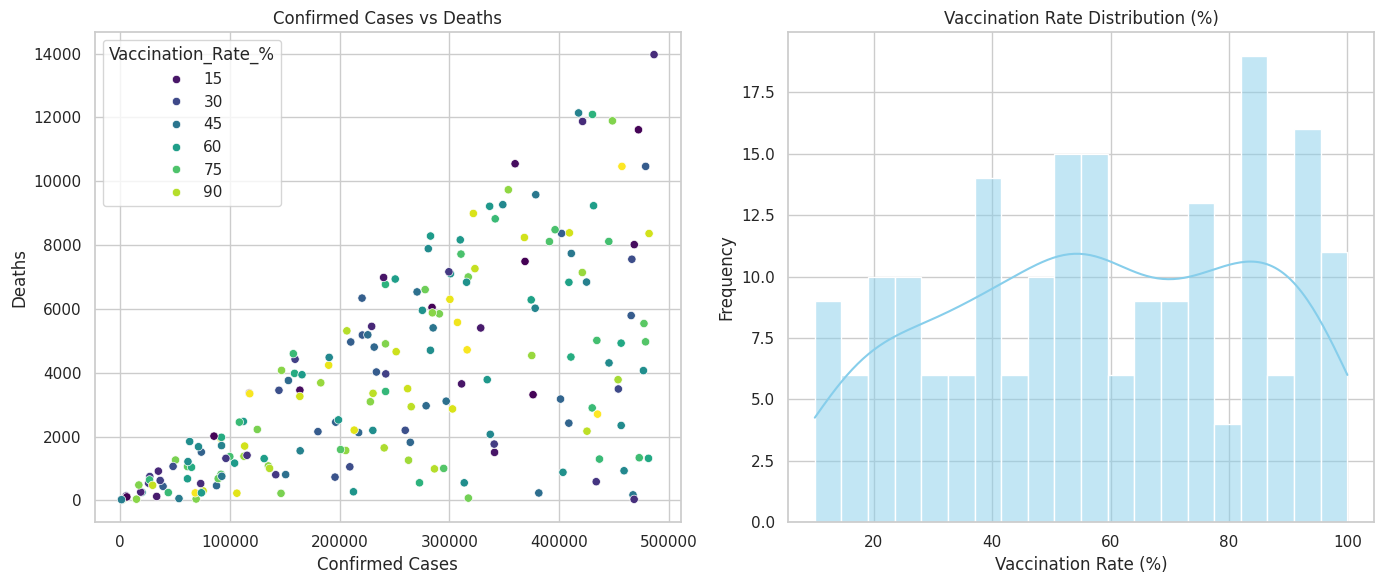

In [5]:
# Set visualization style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 6))

# 1. Distribution of Confirmed Cases vs Deaths
plt.subplot(1, 2, 1)
sns.scatterplot(data=df, x='Confirmed', y='Deaths', hue='Vaccination_Rate_%', palette='viridis')
plt.title('Confirmed Cases vs Deaths')
plt.xlabel('Confirmed Cases')
plt.ylabel('Deaths')

# 2. Vaccination Rate Distribution
plt.subplot(1, 2, 2)
sns.histplot(df['Vaccination_Rate_%'], bins=20, kde=True, color='skyblue')
plt.title('Vaccination Rate Distribution (%)')
plt.xlabel('Vaccination Rate (%)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [6]:
# Save the processed dataset
output_filename = 'Completed_COVID19_Statistics.csv'
df.to_csv(output_filename, index=False)
print(f"Dataset successfully saved as '{output_filename}'")

# Download the file to your local computer
files.download(output_filename)

Dataset successfully saved as 'Completed_COVID19_Statistics.csv'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>